# Classification with NN

## Loading the Data

In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from keras.datasets import fashion_mnist

from keras.models import Sequential
from keras.layers import Dense, Input, Flatten

from keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

Loading [Fashion_mnist dataset](https://www.tensorflow.org/datasets/catalog/fashion_mnist)

In [2]:
# Load data
(X_train_all, y_train_all), (X_test, y_test) = fashion_mnist.load_data()

In [3]:
# Train shape
X_train_all.shape

(60000, 28, 28)

In [4]:
# Test shape
X_test.shape

(10000, 28, 28)

In [5]:
# Split Train to train and val
# Let val size be same as test
X_train, X_val, y_train, y_val = train_test_split(X_train_all,
                                                  y_train_all, 
                                                  test_size=10_000,
                                                  stratify=y_train_all
                                                  ) # underscore in a number is like comma, it's a python thing

In [6]:
# val shape
X_val.shape

(10000, 28, 28)

In [7]:
# what does one observation represent?
X_train[0]

array([[  0,   0,   0,   0,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  99, 154, 179,  93,   9,   0,
          0,   0,   0,   0,   0,  28, 149, 112,   7,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0, 165, 211, 172, 203, 195, 192, 189,
        219, 204, 172, 209, 190, 213, 200, 221, 203,   6,   0,   1,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  22, 207, 174, 195, 166, 174, 125, 157,
        198, 155, 153, 166, 173, 179, 183, 194, 225, 109,   0,   1,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 118, 221, 206, 156, 179, 116, 204, 166,
         71, 238, 153, 150, 218, 175, 179, 197, 244, 178,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 159, 228, 203, 190, 206, 152, 150, 117,
        196,  84, 165, 176, 170, 193, 183, 197, 217, 199,  22,   0,   0,
          0,   0],
       [  

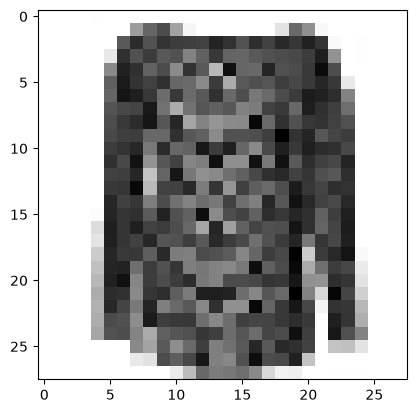

In [10]:
# plot an image
plt.imshow(X_train[0], cmap= 'gray_r')
# plt.xticks([])
# plt.yticks([])

In [9]:
# What are your targets? Return the first 10 values from your training set
??



IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

In [10]:
# How many unique values?
??


IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

In [11]:
??


IPython -- An enhanced Interactive Python

IPython offers a fully compatible replacement for the standard Python
interpreter, with convenient shell features, special commands, command
history mechanism and output results caching.

At your system command line, type 'ipython -h' to see the command line
options available. This document only describes interactive features.

GETTING HELP
------------

Within IPython you have various way to access help:

  ?         -> Introduction and overview of IPython's features (this screen).
  object?   -> Details about 'object'.
  object??  -> More detailed, verbose information about 'object'.
  %quickref -> Quick reference of all IPython specific syntax and magics.
  help      -> Access Python's own help system.

If you are in terminal IPython you can quit this screen by pressing `q`.


MAIN FEATURES
-------------

* Access to the standard Python help with object docstrings and the Python
  manuals. Simply type 'help' (no quotes) to invoke it.

* Ma

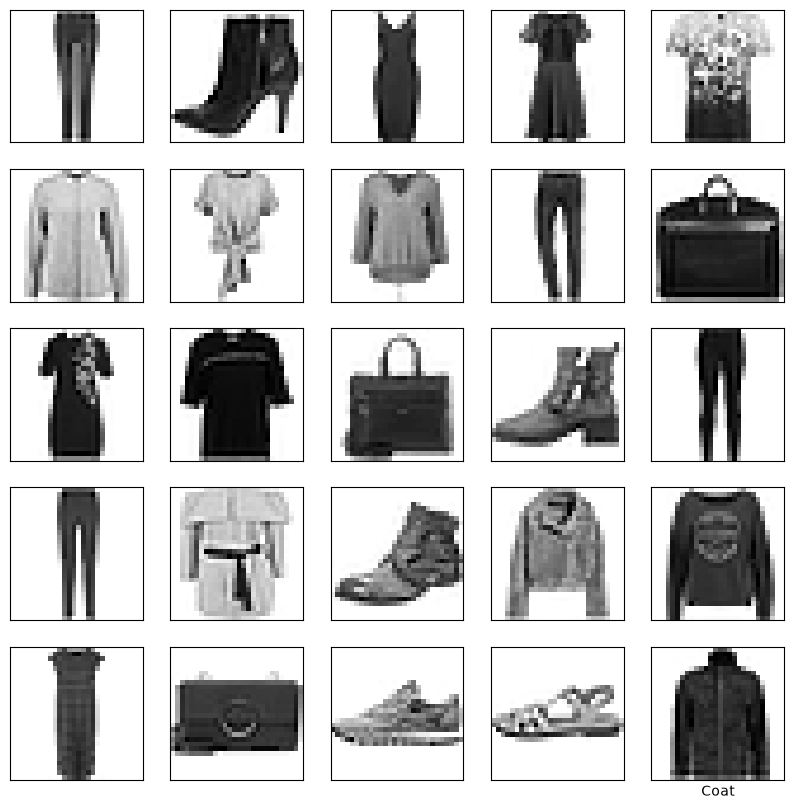

In [35]:
# The labels in Fashion MNIST are 0-9. We need to map them to names:

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig_fashion = plt.figure(figsize=(10, 10))

for i in range(25): 
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray_r")
    plt.xticks([])
    plt.yticks([])
    # y_train[i] is the number; class_names[y_train[i]] is the word

plt.xlabel(class_names[y_train[i]])
plt.show()

In [ ]:
# What is your target balance?
# Hint: convert y_train to series using pd.Series to use value_counts()
??

9    5000
0    5000
7    5000
6    5000
2    5000
3    5000
8    5000
5    5000
1    5000
4    5000
dtype: int64

## Preprocessing

In [ ]:
#from sklearn.preprocessing import MinMaxScaler

#scaler = MinMaxScaler()
#scaler.fit(x_train)

In [ ]:
# Manual MinMax Scaling
X_train = 
X_val = 
X_test = 


In [ ]:
# check one of the scaled  images
??

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

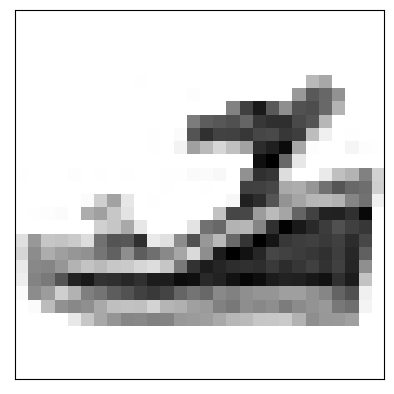

In [ ]:
# Visualize it
plt.imshow( ________ , cmap="gray_r");
plt.xticks([])
plt.yticks([]);

## Output Classification Loss Functions for Neural Networks

In deep learning, the combination of your **final layer's activation function** and your **loss function** must perfectly match the type of classification task you are solving. If they do not match, your network will calculate the wrong gradients and fail to learn.

---

### Classification Architecture Matrix

Here is the definitive blueprint for setting up the output and loss configurations in modern neural networks:

| Classification Type | Number of Classes | Target Label Format | Output Activation | Matching Loss Function |
| :--- | :--- | :--- | :--- | :--- |
| **Binary** | Exactly 2 | Scalar integers (`0` or `1`) | `sigmoid` | **`binary_crossentropy`** |
| **Multi-class (Integer)** | 3 or more | Scalar integers (`0`, `1`, `2`, ...) | `softmax` | **`sparse_categorical_crossentropy`** |
| **Multi-class (One-Hot)** | 3 or more | Arrays (`[1, 0, 0]`, `[0, 1, 0]`, ...) | `softmax` | **`categorical_crossentropy`** |

---

### One-hot Encoding Targets
---

- `keras`' has built-in `to_categorical` function to convert the target to matrix of 0s and 1s if the target is a string
- If you convert your targets into a matrix of 0s and 1s using `to_categorical(y)`, you must compile your model with `categorical_crossentropy`.
- If you leave your targets as raw integers (like 0, 1, 2... 9), you do not need to use `to_categorical`. You just change your loss function to `sparse_categorical_crossentropy`. This saves computer memory because you don't have to create large matrices of zeros


In [13]:
# Sample code
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# Original string targets
y_train_sample = ["cat", "dog", "bird", "cat", "dog"]

# Step 1: Convert strings to integer labels
encoder = LabelEncoder()
y_train_labeled_sample = encoder.fit_transform(y_train_sample)
print(y_train_labeled_sample)

[1 2 0 1 2]


In [14]:
# Step 2: Convert integer labels to one-hot encoding
y_train_encoded_sample = to_categorical(y_train_labeled_sample)

print(y_train_encoded_sample)

[[0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### Understanding `metrics=['acc']` in Neural Networks

The `metrics=['acc']` or `metrics=['accuracy']` argument is used during the model compilation step (`model.compile()`) in deep learning frameworks like Keras and TensorFlow. It tells the computer to calculate and display the **accuracy** score after each round of training (epoch).

Unlike the **loss function**, which the computer uses behind the scenes to update its internal weights, **metrics** are entirely for humans to look at so you can easily understand how well your AI is performing.


In [15]:
# Step 1
model = Sequential([
    Input( shape=(28,28) ),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

# Step2: Compile
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['acc']
             )


#Step3: Fitting

# configure EarlyStopping parameters
es=EarlyStopping(monitor='val_loss',
                 patience=5,
                 restore_best_weights=True
                )

history = model.fit(X_train,
                    y_train,
                    validation_data=(X_val, y_val),
                    epochs=100,
                    batch_size=128,
                    callbacks=es
                   )

Epoch 1/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - acc: 0.5849 - loss: 3.0443 - val_acc: 0.6029 - val_loss: 1.3005
Epoch 2/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.6526 - loss: 1.0939 - val_acc: 0.6789 - val_loss: 1.0313
Epoch 3/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.6799 - loss: 0.9148 - val_acc: 0.6883 - val_loss: 0.9185
Epoch 4/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7055 - loss: 0.7895 - val_acc: 0.7210 - val_loss: 0.8395
Epoch 5/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7217 - loss: 0.7187 - val_acc: 0.7236 - val_loss: 0.7381
Epoch 6/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7320 - loss: 0.6707 - val_acc: 0.7403 - val_loss: 0.6897
Epoch 7/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7387 - loss: 0.6298 - val_acc: 0.7406 - val_loss: 0.6678
Epoch 8/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7474 - loss: 0.6026 - val_acc: 0.7491 - val_loss: 0.6123
Epoch 9/100
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

In [16]:
# Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,952 (617.00 KB)

 Trainable params: 52,650 (205.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 105,302 (411.34 KB)

In [17]:
# History dataframe
history_df=pd.DataFrame(history.history)
history_df.head()

,acc,loss,val_acc,val_loss
0,0.58488,3.044270,0.6029,1.300496
1,0.65256,1.093928,0.6789,1.031286
2,0.67992,0.914791,0.6883,0.918472
3,0.70554,0.789516,0.7210,0.839467
4,0.72170,0.718680,0.7236,0.738073


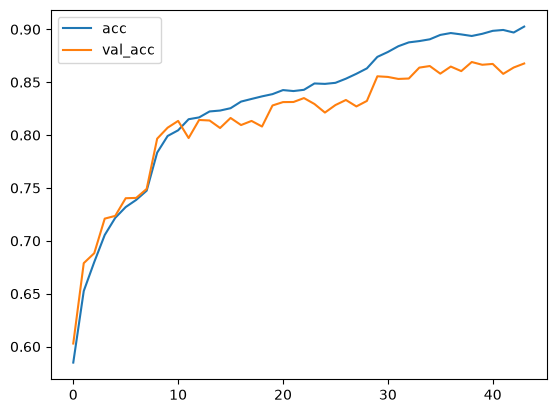

In [18]:
# Plot train and validation accuracy 
history_df[['acc', 'val_acc']].plot();

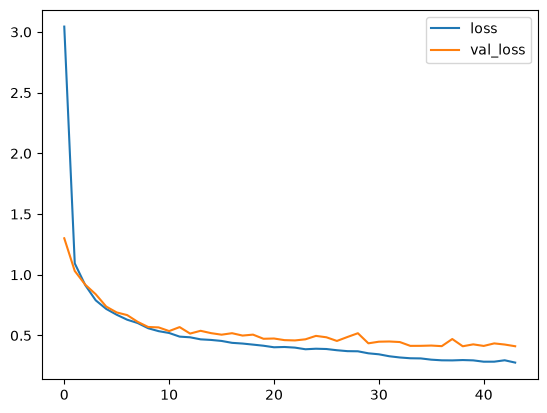

In [19]:
# Plot train and validation loss as bar chart
history_df[['loss', 'val_loss']].plot();

### When would I monitor `metric` instead of `loss`?

EarlyStopping can monitor either validation loss or a validation metric. The choice determines which epoch is considered the best and when training stops.

#### **1. Monitoring val_loss (Default Recommendation):**
- Measures how well predicted probabilities match the actual classes.
- Detects improvements even when classification accuracy remains unchanged.
    - `Epoch 1:` Predicts Dog with 60% probability → Correct
    - `Epoch 2:` Predicts Dog with 90% probability → Correct
    - _Probability (confidence) improved while accuracy (right predicted label) stayed the same_
    
#### **2. Monitoring Classification Metrics**

When the main objective is to maximize a specific evaluation metric, we can monitor that metric instead.

| Metric          | When to monitor it                                                                                       |
| --------------- | -------------------------------------------------------------------------------------------------------- |
| `val_precision` | When false positive predictions are particularly costly (e.g., legitimate emails classified as spam)     |
| `val_recall`    | When missing actual positive cases is particularly costly (e.g., detecting diseases)                     |
| `val_auc`       | When we care about the model's ability to distinguish classes across different classification thresholds |

**Note that you can also modify the threshold's value to optimize for your metric score)**

### Class Weights

The `class_weight` helps with **imbalanced datasets**.

When a dataset is imbalanced, it means you have way more examples of one category than another. If you train a model normally on this data, the model will bias toward the majority class and ignore the minority class. `class_weight` balances the scales by penalizing the model more heavily when it misclassifies the rare category.

---

In [20]:
# Sample Code

# import compute_class_weight from sklearn.utils 
from sklearn.utils.class_weight import compute_class_weight

# Example of an imbalanced target: 3 shirts vs. 1 short
dummy_y = ['shirt', 'short', 'shirt', 'shirt']

# Calculate class weights to compensate for class imbalance
class_weights = compute_class_weight( 
                    class_weight='balanced',   # Automatically assign higher weights to minority classes
                    classes=np.array(['short', 'shirt']), # Unique classes (order determines the output order)
                    y=dummy_y                            # Target labels
)

class_weights

array([2.        , 0.66666667])

In [21]:
# compute class weight for y_train
c_weights = compute_class_weight( 
                    class_weight='balanced',   # Automatically assign higher weights to minority classes
                    classes=np.array(y_train), # Unique classes (order determines the output order)
                    y=y_train                            # Target labels
)

c_weights

array([1., 1., 1., ..., 1., 1., 1.], shape=(50000,))

In [22]:
# convert the c_weights to dictionay holding class and weight

class_weight_dict = dict( zip(np.unique(y_train), c_weights) )
class_weight_dict

{np.uint8(0): np.float64(1.0),
 np.uint8(1): np.float64(1.0),
 np.uint8(2): np.float64(1.0),
 np.uint8(3): np.float64(1.0),
 np.uint8(4): np.float64(1.0),
 np.uint8(5): np.float64(1.0),
 np.uint8(6): np.float64(1.0),
 np.uint8(7): np.float64(1.0),
 np.uint8(8): np.float64(1.0),
 np.uint8(9): np.float64(1.0)}

In [23]:
# Use class_weight in the model fit

'''
history = model.fit(X_train,
                    y_train,
                    validation_data=(X_val,y_val),
                    epochs=100,
                    batch_size=128,
                    ________ = ________
                    callbacks=[es]
                   )
'''

'\nhistory = model.fit(X_train,\n                    y_train,\n                    validation_data=(X_val,y_val),\n                    epochs=100,\n                    batch_size=128,\n                    ________ = ________\n                    callbacks=[es]\n                   )\n'

#### How Are Class Weights Calculated?

When using `class_weight="balanced"`, Scikit-learn calculates each class weight using:

$$
w_i = \frac{N}{K \times N_i}
$$

Where:
- $w_i$: Weight assigned to class $i$
- $N$: Total number of observations
- $K$: Number of unique classes
- $N_i$: Number of observations belonging to class $i$



## Prediction

In [24]:
# What is X_test shape?
X_test.shape

(10000, 28, 28)

In [25]:
# check what is x_test[0] looks like
X_test[0].shape

(28, 28)

In [26]:
# check what is x_test[:1] looks like
X_test[:1].shape

(1, 28, 28)

In [27]:
# what happens if you choose the first 3 images?
X_test[:3].shape

(3, 28, 28)

#### Understanding Indexing: `x_test[0]` vs. `x_test[:1]`

- Neural networks **always expect inputs to arrive in batches**, even if you are only predicting a single image. They look for a shape configuration of:

$[\text{(Batch Size, Height, Width, Channels)}\$]

```python
# ❌ THIS WILL THROW AN ERROR
# The model expects a 3D/4D batch, but receives a 2D array (28, 28)
model.predict(X_test[0]) 
```

```python
# This works instantly! Shape is already (1, 28, 28)
model.predict(X_test[:1]) 
```

---

##### Summary Reference Comparison

| Code Syntax | Operation Type | Resulting Shape (on 3D Input) | Use Case |
| :--- | :--- | :--- | :--- |
| **`X_test[0]`** | Integer Indexing | `(28, 28)` *(Dimensions Dropped)* | Plotting a single image using `plt.imshow()`. |
| **`X_test[:1]`** | Array Slicing | `(1, 28, 28)` *(Dimensions Maintained)* | Passing a single test sample to `model.predict()`. |


In [28]:
# make single prediction only
single_pred = model.predict(X_test[:1])
single_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


array([[2.0398332e-08, 4.7975139e-09, 5.4181390e-05, 1.6140954e-09,
        3.3740580e-08, 2.2560980e-05, 5.0727611e-10, 1.5895618e-02,
        3.8209214e-06, 9.8402381e-01]], dtype=float32)

In [29]:
# Geting the `maximum probability`
max(single_pred[0])

np.float32(0.9840238)

In [30]:
# Geting the `Class of maximum probability`
# argmax` looks at a list of numbers, finds the highest number, and returns its index position

pred_label = np.argmax(single_pred[0])
pred_label

np.int64(9)

In [32]:
# What are my classes?
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [33]:
# what is the predicted class?
class_names[9]

'Ankle boot'

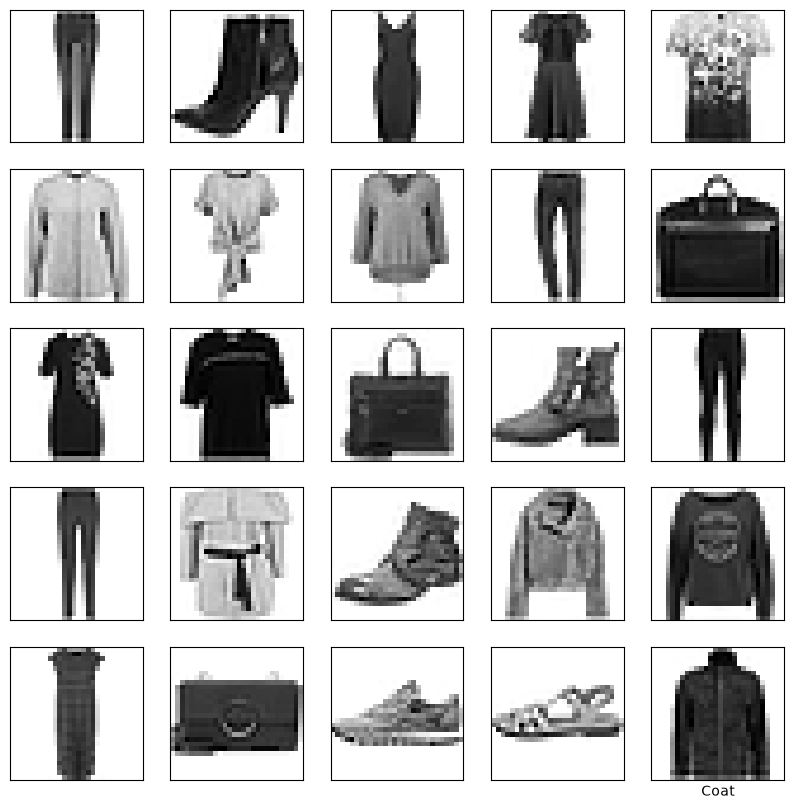

In [36]:
# saved figure
fig_fashion

In [39]:
# Prediction on last 10 items
X_test_sample = X_test[-10:]
X_test_sample.shape

(10, 28, 28)

In [40]:
y_pred_sample = model.predict(X_test_sample[-10:])
y_pred_sample

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 1.0000000e+00, 0.0000000e+00, 1.9370242e-36,
        0.0000000e+00, 0.0000000e+00],
       [1.5740576e-01, 9.5371863e-05, 1.1639840e-01, 5.8811256e-03,
        2.8206783e-03, 3.3836047e-13, 7.1700507e-01, 1.4216636e-18,
        3.9364351e-04, 4.1068499e-27],
       [7.8793506e-11, 5.5855001e-13, 1.7562795e-16, 1.1058836e-12,
        2.5094136e-20, 3.1850631e-19, 1.7445784e-11, 2.1668342e-20,
        1.0000000e+00, 1.0180508e-25],
       [9.5827663e-17, 1.0257486e-11, 6.3319185e-08, 2.7905080e-19,
        6.7886587e-13, 7.6922321e-14, 1.1571271e-19, 1.1804619e-05,
        2.0242464e-12, 9.9998808e-01],
       [1.5420663e-09, 9.9999571e-01, 3.7839229e-06, 4.0914863e-08,
        5.5379894e-07, 1.9394320e-30, 2.1474128e-13, 1.5123088e-25,
        8.5003546e-11, 0.0000000e+00],
       [4.0283659e-15, 3.9155253e-14, 9.5672199e-09, 1.7712500e-17,
        8.9552380e-15, 1.5769272e-10, 1.3290203e-18, 1.44

In [42]:
# show the probability for each class for the first sample

for class_name, proba in zip(class_names, y_pred_sample[0]):
    print(f'{class_name}: {proba:.4f}')


T-shirt/top: 0.0000
Trouser: 0.0000
Pullover: 0.0000
Dress: 0.0000
Coat: 0.0000
Sandal: 1.0000
Shirt: 0.0000
Sneaker: 0.0000
Bag: 0.0000
Ankle boot: 0.0000


In [ ]:
# what are the indexes (class label) for the first sample
# use argmax to return the index of the maximum in each vector
y_pred_label = np.argmax()

T-shirt/top 1.7694116e-10
Trouser 1.35225515e-14
Pullover 5.2238106e-11
Dress 1.3769045e-11
Coat 1.6334856e-13
Sandal 0.9997255
Shirt 4.5222018e-15
Sneaker 9.738918e-09
Bag 7.515851e-14
Ankle boot 0.00027440782


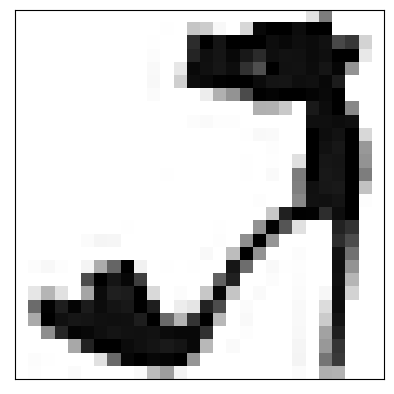

In [ ]:
# Visualize the first sample. Does it match the prediction?
plt.imshow(________, cmap="gray_r");
plt.xticks([])
plt.yticks([]);

## Evaluating the Model

In [50]:
# Predict on X_test
y_pred = model.predict(X_test)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


array([[2.0398334e-08, 4.7975606e-09, 5.4181397e-05, ..., 1.5895560e-02,
        3.8209218e-06, 9.8402393e-01],
       [1.3290888e-04, 1.1170255e-06, 9.9655211e-01, ..., 1.0053273e-21,
        1.5918157e-06, 5.5194273e-21],
       [4.4337287e-11, 1.0000000e+00, 3.1358439e-08, ..., 1.1186005e-33,
        3.4106379e-13, 0.0000000e+00],
       ...,
       [1.2705039e-09, 3.4346170e-31, 2.3806825e-20, ..., 3.2613446e-13,
        1.0000000e+00, 2.5389513e-23],
       [1.1069206e-08, 9.9999666e-01, 2.1998233e-06, ..., 9.0904471e-27,
        1.9869310e-10, 0.0000000e+00],
       [3.0344662e-08, 4.9861733e-20, 1.0106237e-11, ..., 3.0839842e-04,
        9.7111115e-07, 1.4035351e-05]], shape=(10000, 10), dtype=float32)

In [52]:
# Convert predictions to labels
y_pred_label= np.argmax(y_pred, axis=1)
y_pred_label

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,))

In [53]:
y_pred_label.size

10000

In [54]:
# what is the accuracy?
accuracy_score(y_test, y_pred_label)

0.8638

In [55]:
# compare pred with true label using evaluate
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.8638 - loss: 0.4305


[0.4304902255535126, 0.8637999892234802]

> The first value is always the loss, but the second value depends on which metrics you specified in `model.compile()`

In [57]:
# What is the recall score for each class?
recall_score(y_test, y_pred_label, average=None)

array([0.86 , 0.956, 0.803, 0.871, 0.777, 0.975, 0.562, 0.953, 0.952,
       0.929])

### Error Analysis

In [58]:
# Classification Report
print(classification_report(y_test, y_pred_label))

              precision    recall  f1-score   support

           0       0.78      0.86      0.82      1000
           1       0.99      0.96      0.97      1000
           2       0.73      0.80      0.76      1000
           3       0.89      0.87      0.88      1000
           4       0.74      0.78      0.76      1000
           5       0.95      0.97      0.96      1000
           6       0.68      0.56      0.61      1000
           7       0.93      0.95      0.94      1000
           8       0.98      0.95      0.96      1000
           9       0.97      0.93      0.95      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



#### Macro vs Weighted Averages

**1. Macro Average:** Calculates the metric for each class and takes their simple average, giving **equal importance to all classes**.

$$
\text{Macro Average} = \frac{\sum_{i=1}^{K} M_i}{K}
$$

Where:
- $M_i$: Precision, recall, or F1-score for class $i$
- $N_i$: Support of class $i$
- $K$: Number of classes

**2. Weighted Average:** Calculates the metric for each class, weighted by its **support** (number of actual observations).

$$
\text{Weighted Average} = \frac{\sum_{i=1}^{K} M_i \times N_i}{\sum_{i=1}^{K} N_i}
$$


**3. How to Interpret the Averages:**
- **Macro averages** help assess whether the model performs well across all classes, including minority ones.
- **Weighted averages** reflect class frequencies, so majority classes have greater influence.
- A **large gap** between macro and weighted averages suggests uneven performance across classes. Always inspect individual class scores to identify the problem.



In [ ]:
# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_label)
conf_matrix

array([[883,   3,   7,  25,   5,   1,  67,   0,   9,   0],
       [  5, 970,   2,  19,   2,   0,   1,   0,   1,   0],
       [ 24,   0, 788,  15, 110,   0,  61,   0,   2,   0],
       [ 35,   6,   5, 902,  31,   1,  16,   0,   4,   0],
       [  2,   1,  93,  33, 827,   1,  39,   0,   4,   0],
       [  0,   0,   0,   0,   0, 963,   0,  13,   1,  23],
       [190,   2,  92,  31,  93,   0, 582,   0,  10,   0],
       [  0,   0,   0,   0,   0,  29,   0, 933,   0,  38],
       [ 11,   0,   2,   6,   2,   3,   4,   3, 969,   0],
       [  0,   0,   0,   0,   0,   5,   1,  26,   0, 968]])

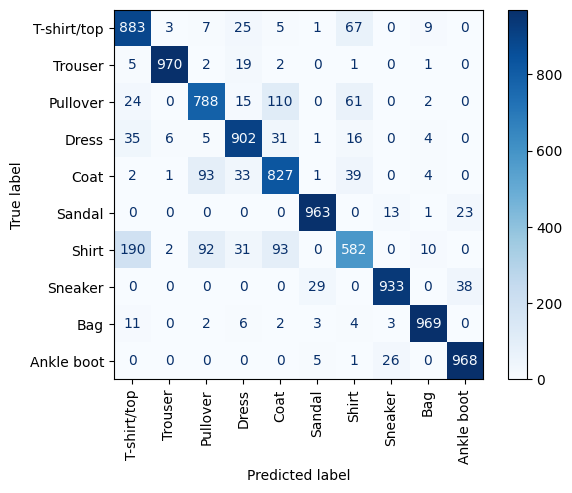

In [ ]:
# ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix= conf_matrix,
    display_labels=class_names,
).plot(cmap='blues', xticks_rotation=90);


##### List of all the images the model got wrong

In [ ]:
# np.where returns the indexes of the obervations that meets the condition
wrong_indices = ??

array([  12,   17,   23, ..., 9979, 9985, 9991])

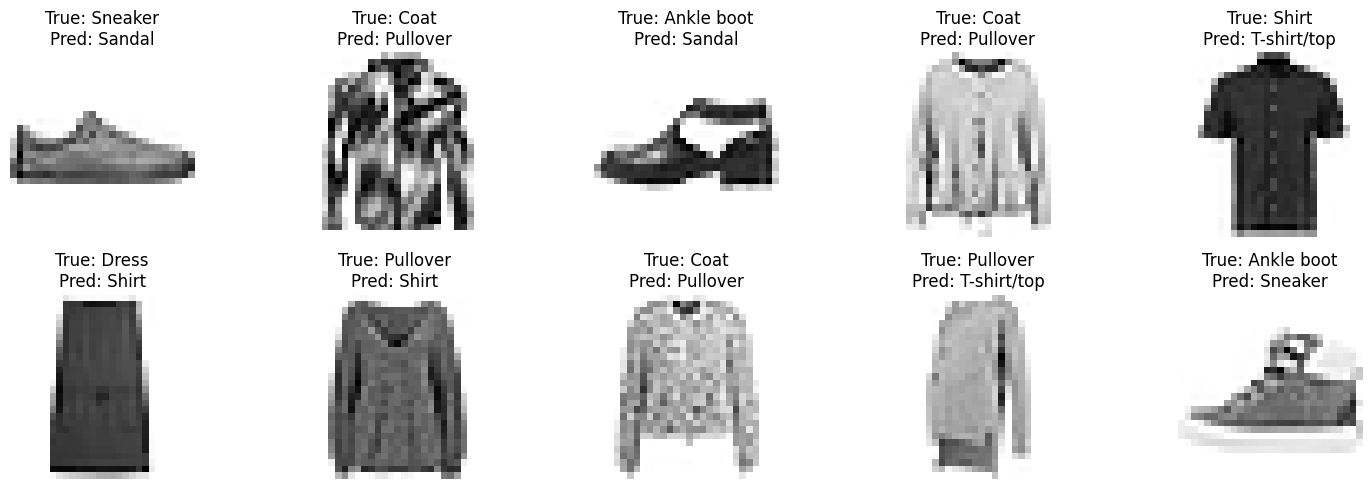

In [ ]:
# Display the first 10 incorrect predictions
plt.figure(figsize=(15, 5))

for i, idx in enumerate(wrong_indices[0][:10]):
    plt.subplot(2, 5, i + 1)

    # Display the image
    plt.imshow(X_test[idx], cmap="gray_r")

    # Show actual and predicted class names
    true_class = class_names[y_test[idx]]
    pred_class = class_names[y_pred_label[idx]]

    plt.title(f"True: {true_class}\nPred: {pred_class}")
    plt.axis("off")

plt.tight_layout()
plt.show()

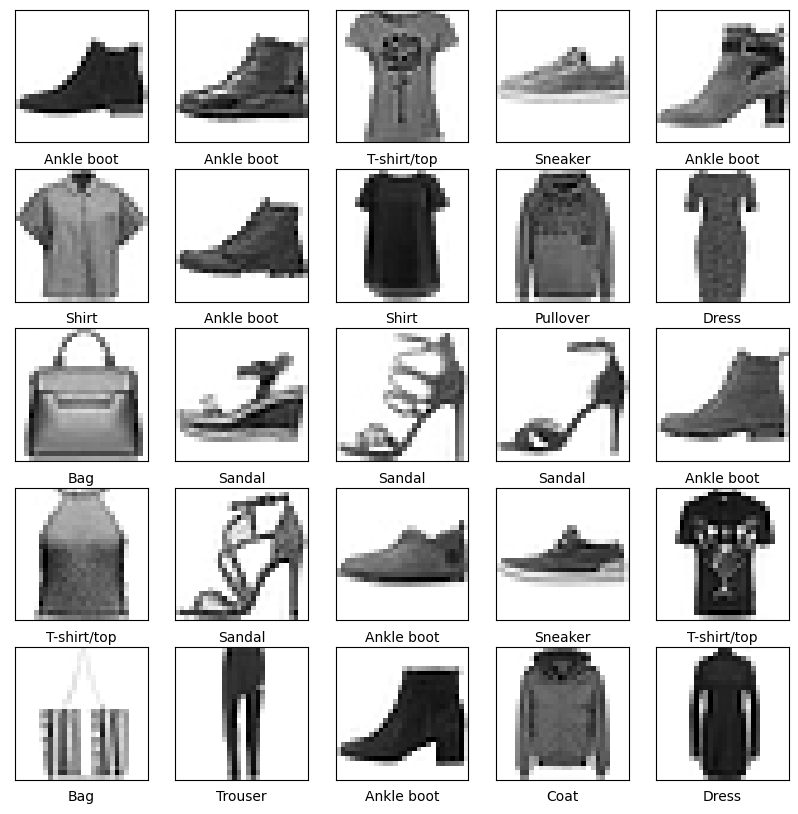

In [ ]:
# To remind ourselves of the classes
fig_fashion

#### More enhancement?

- Data Augmentation: Flipping, mirroring, zooming,...
- Use CNN instead of flatting the image